# HOUSE PRICE PREDICTION PROJECT 

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

In [2]:
csv_1 = pd.read_csv(r"Housing.csv")
csv_1.head()

,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus,price
0,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished,13300000
1,8960,4,4,4,yes,no,no,no,yes,3,no,furnished,12250000
2,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished,12250000
3,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished,12215000
4,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished,11410000


In [3]:
csv_1.shape

(545, 13)

In [4]:
# Reorder columns, moving 'price' to the end
cols = [col for col in csv_1.columns if col != 'price'] + ['price']
csv_1 = csv_1[cols]

In [5]:
csv_1.to_csv("Housing_clean.csv", index=False)

In [6]:
# handling missing value
csv_1.isnull().sum()

area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
price               0
dtype: int64

# label encoding 

# mainroad

In [7]:
from sklearn.preprocessing import LabelEncoder

In [8]:
end_data = csv_1["mainroad"]

In [9]:
le = LabelEncoder()

In [10]:
csv_1["mainroad"] = le.fit_transform(end_data)

# guestroom

In [11]:
end_data = csv_1["guestroom"]

In [12]:
le = LabelEncoder()

In [13]:
csv_1["guestroom"] = le.fit_transform(end_data)

# basement

In [14]:
end_data = csv_1["basement"]

In [15]:
le = LabelEncoder()

In [16]:
csv_1["basement"] = le.fit_transform(end_data)

# hotwaterheating

In [17]:
end_data = csv_1["hotwaterheating"]

In [18]:
le = LabelEncoder()

In [19]:
csv_1["hotwaterheating"] = le.fit_transform(end_data)

# airconditioning

In [20]:
end_data = csv_1["airconditioning"]

In [21]:
le = LabelEncoder()

In [22]:
csv_1["airconditioning"] = le.fit_transform(end_data)

# prefarea

In [23]:
end_data = csv_1["prefarea"]

In [24]:
le = LabelEncoder()

In [25]:
csv_1["prefarea"] = le.fit_transform(end_data)

# OneHotEncoding 

In [26]:
from sklearn.preprocessing import OneHotEncoder

# furnishingstatus

In [27]:
csv_1["furnishingstatus"].unique()

<ArrowStringArray>
['furnished', 'semi-furnished', 'unfurnished']
Length: 3, dtype: str

In [28]:
end_data = csv_1[["furnishingstatus"]]

In [29]:
on = OneHotEncoder(sparse_output=False)

In [30]:
dd = on.fit_transform(end_data)

In [31]:
en_furnishingstatus = pd.DataFrame(dd, columns=on.get_feature_names_out(), index=csv_1.index)

In [32]:
csv_1 = pd.concat([csv_1, en_furnishingstatus], axis=1)

In [33]:
csv_1 = csv_1.drop("furnishingstatus", axis=1)

In [34]:
# remove dummy variable trap columns
csv_1 = csv_1.drop("furnishingstatus_furnished", axis=1)

In [35]:
cols = [col for col in csv_1.columns if col != "price"] + ["price"]
csv_1 = csv_1[cols]

In [36]:
# outlier detection

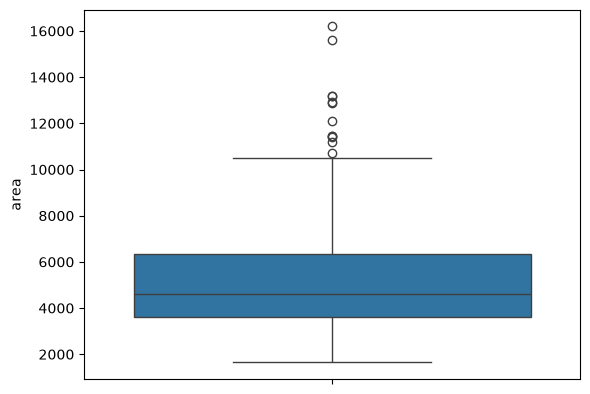

In [37]:
sns.boxplot(csv_1["area"])
plt.show()

In [38]:
# csv_1[csv_1["area"] > 10500][["area", "price"]]

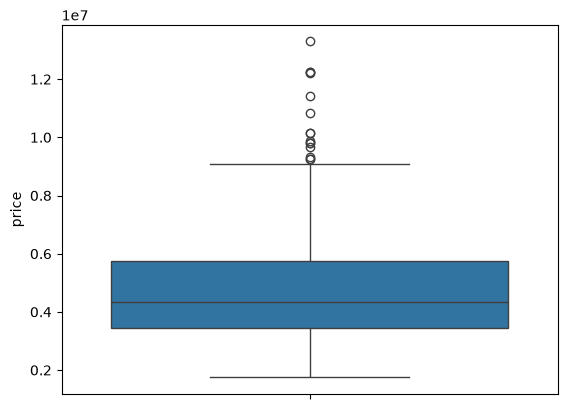

In [39]:
sns.boxplot(csv_1["price"])
plt.show()

# Regression 

# Linear Regression 

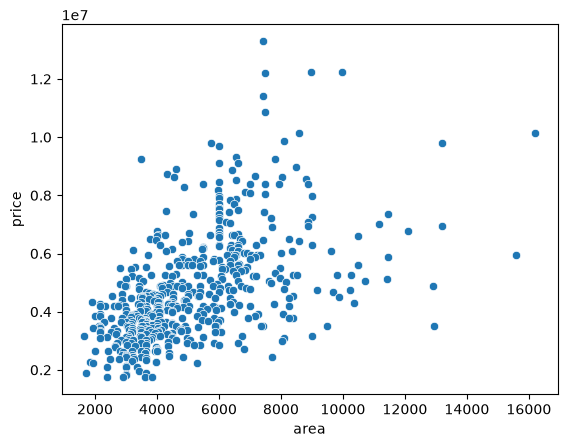

In [40]:
sns.scatterplot(x="area", y="price", data=csv_1)
plt.show()

# 1 simple Linear Regression

In [41]:
x = csv_1[["area"]]
y = csv_1["price"]

In [42]:
from sklearn.model_selection import train_test_split

In [43]:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.2, random_state=40)

In [44]:
from sklearn.linear_model import LinearRegression

In [45]:
lr = LinearRegression()

In [46]:
lr.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[449.37]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['area']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.389e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [47]:
# lr.predict([[7420]])

In [48]:
lr.score(x_test, y_test)*100

24.11372375948394

In [49]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [50]:
print(mean_squared_error(y_test, lr.predict(x_test)))
print(mean_absolute_error(y_test, lr.predict(x_test)))
print(np.sqrt(mean_squared_error(y_test, lr.predict(x_test))))

3263874991997.8794
1310624.989723077
1806619.7696244442


# cross_validation 

In [51]:
from sklearn.linear_model import LinearRegression 

In [52]:
from sklearn.model_selection import KFold, cross_val_score

In [53]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [54]:
score = cross_val_score(LinearRegression(), x,y, cv=kf)

In [55]:
print(score*100)

[27.28785187 25.9747848  -5.74141382 33.87908831 31.72097873]


In [56]:
print(score.mean()*100, score.std()*100)

22.624257978867966 14.470715316586844


# 1 Multiple linearRegression

In [57]:
x1 = csv_1.drop(columns=["price","price_category"], errors="ignore")
y1 = csv_1["price"]

In [58]:
from sklearn.model_selection import train_test_split

In [59]:
x1_train, x1_test, y1_train, y1_test = train_test_split(x1,y1, test_size=0.2, random_state=42)

In [60]:
from sklearn.linear_model import LinearRegression

In [61]:
lr = LinearRegression()

In [62]:
lr.fit(x1_train, y1_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[ 235.97, 76778.7 ,1094444.79,..., 629890.57,-126881.82,-413645.06]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['area','bedrooms','bathrooms',...,'prefarea', 'furnishingstatus_semi-furnished','furnishingstatus_unfurnished']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.6e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [63]:
lr.score(x1_test, y1_test)*100

65.29242642153186

In [64]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [65]:
print(mean_squared_error(y1_test, lr.predict(x1_test)))
print(mean_absolute_error(y1_test, lr.predict(x1_test)))
print(np.sqrt(mean_squared_error(y1_test, lr.predict(x1_test))))

1754318687330.6628
970043.4039201637
1324506.9600914384


# cross_validation

In [66]:
from sklearn.linear_model import LinearRegression

In [67]:
from sklearn.model_selection import KFold, cross_val_score

In [68]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [69]:
score = cross_val_score(LinearRegression(), x1,y1, cv=kf)

In [70]:
print(score*100)

[65.29242642 71.20827449 49.27551878 65.80389212 64.64370895]


In [71]:
print(score.mean()*100, score.std()*100)

63.24476415125715 7.365547047100176


# Lasso Regression

In [72]:
x2 = csv_1.drop(columns=["price","price_category"], errors="ignore")
y2 = csv_1["price"]

In [73]:
from sklearn.model_selection import train_test_split

In [74]:
x2_train, x2_test, y2_train, y2_test = train_test_split(x2, y2, test_size=0.2, random_state=42)

In [75]:
from sklearn.preprocessing import StandardScaler

In [76]:
ss = StandardScaler()

In [77]:
x2_train = ss.fit_transform(x2_train)

In [78]:
x2_test = ss.transform(x2_test)

In [79]:
from sklearn.linear_model import Lasso

In [80]:
ll = Lasso(alpha=0.5)

In [81]:
ll.fit(x2_train, y2_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",0.5
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary <warm_start>`.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'
Name,Type,Value


In [82]:
print(ll.score(x2_train, y2_train)*100, ll.score(x2_test, y2_test)*100)

68.5943898855312 65.29241355160693


In [83]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [84]:
import numpy as np

In [85]:
print(mean_squared_error(y2_test, ll.predict(x2_test)))
print(mean_absolute_error(y2_test, ll.predict(x2_test)))
print(np.sqrt(mean_squared_error(y2_test, ll.predict(x2_test))))

1754319337850.059
970043.4046464945
1324507.2056618112


# cross_validation 

In [86]:
from sklearn.pipeline import make_pipeline

In [87]:
from sklearn.model_selection import KFold, cross_val_score

In [88]:
from sklearn.linear_model import Lasso

In [89]:
from sklearn.preprocessing import StandardScaler

In [90]:
kf2 = KFold(n_splits=5, shuffle=True, random_state=42)

In [91]:
make = make_pipeline(StandardScaler(), Lasso(alpha=0.5))

In [92]:
score = cross_val_score(make, x2,y2, cv=kf2)

In [93]:
print(score*100)

[65.29241355 71.20827617 49.27556745 65.8038957  64.64370595]


In [94]:
print(score.mean()*100, score.std()*100)

63.244771762891894 7.365528367328834


# Ridge Regression

In [95]:
x3 = csv_1.drop(columns=["price","price_category"], errors="ignore")
y3 = csv_1["price"]

In [96]:
from sklearn.model_selection import train_test_split

In [97]:
x3_train, x3_test, y3_train, y3_test = train_test_split(x3, y3, test_size=0.2, random_state=42)

In [98]:
from sklearn.preprocessing import StandardScaler

In [99]:
s1 = StandardScaler()

In [100]:
x3_train = s1.fit_transform(x3_train)

In [101]:
x3_test = s1.transform(x3_test)

In [102]:
from sklearn.linear_model import Ridge

In [103]:
ri = Ridge(alpha=0.5)

In [104]:
ri.fit(x3_train, y3_train)

,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",0.5
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' 

In [105]:
print(ri.score(x3_train, y3_train)*100, ri.score(x3_test, y3_test)*100)

68.59435891800211 65.28730832719334


In [106]:
from sklearn.metrics import mean_squared_error, mean_absolute_error 

In [107]:
print(mean_squared_error(y3_test, ri.predict(x3_test)))
print(mean_absolute_error(y3_test, ri.predict(x3_test)))
print(np.sqrt(mean_squared_error(y3_test, ri.predict(x3_test))))

1754577385004.278
969950.271328731
1324604.6145942109


# cross validation

In [108]:
from sklearn.pipeline import make_pipeline

In [109]:
from sklearn.linear_model import Ridge

In [110]:
from sklearn.preprocessing import StandardScaler 

In [111]:
from sklearn.model_selection import KFold, cross_val_score

In [112]:
kf3 = KFold(n_splits=5, shuffle=True, random_state=42)

In [113]:
make1 = make_pipeline(StandardScaler(), Ridge(alpha=0.5))

In [114]:
score =cross_val_score(make1, x3,y3, cv=kf3)

In [115]:
print(score*100)

[65.28730833 71.20643053 49.29737037 65.8173923  64.65009719]


In [116]:
print(score.mean()*100, score.std()*100)

63.251719744704914 7.357758436402978


# Decison Tree Regression Algorithm 

In [117]:
x11 = csv_1.drop(columns=["price","price_category"], errors="ignore")
y11 = csv_1["price"]

In [118]:
from sklearn.model_selection import train_test_split

In [119]:
x11_train, x11_test, y11_train, y11_test = train_test_split(x11,y11, test_size=0.2, random_state=42)

In [120]:
from sklearn.tree import DecisionTreeRegressor

In [121]:
rr = DecisionTreeRegressor(max_depth= 6, min_samples_leaf= 3, min_samples_split= 10)
rr.fit(x11_train, y11_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",6
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",3
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with

In [122]:
rr.score(x11_train,y11_train)*100, rr.score(x11_test,y11_test)*100

(77.41144065143827, 43.96404060514726)

In [123]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [124]:
print(mean_squared_error(y11_test, rr.predict(x11_test)))
print(mean_absolute_error(y11_test, rr.predict(x11_test)))
print(np.sqrt(mean_squared_error(y11_test, rr.predict(x11_test))))

2832376930834.448
1282409.0782992372
1682966.7052067453


# Cross Validation

In [125]:
from sklearn.tree import DecisionTreeRegressor

In [126]:
from sklearn.model_selection import KFold, cross_val_score

In [127]:
kf31 = KFold(n_splits=5, shuffle=True, random_state=42)

In [128]:
score = cross_val_score(DecisionTreeRegressor(max_depth= 6, min_samples_leaf= 3, min_samples_split= 10), x11,y11, cv=kf31)

In [129]:
print(score*100)

[43.96404061 60.96485258 25.22732521 47.88178508 50.77794244]


In [130]:
print(score.mean()*100, score.std()*100)

45.76318918439682 11.710554330086197


# K-Neighbors Regressor

In [131]:
x12 = csv_1.drop(columns=["price","price_category"], errors="ignore")
y12 = csv_1["price"]

In [132]:
from sklearn.model_selection import train_test_split

In [133]:
x12_train, x12_test, y12_train, y12_test = train_test_split(x12,y12, test_size=0.2, random_state=42)

In [134]:
from sklearn.preprocessing import StandardScaler

In [135]:
s1 = StandardScaler()

In [136]:
x12_train = s1.fit_transform(x12_train)

In [137]:
x12_test = s1.transform(x12_test)

In [138]:
from sklearn.neighbors import KNeighborsRegressor

In [139]:
kk = KNeighborsRegressor(n_neighbors=5)

In [140]:
kk.fit(x12_train,y12_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"effective_metric_ effective_metric_: str or callableThe distance metric to use. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'
"effective_metric_params_ effective_metric_params_: dictAdditional keyword arguments for the metric function. For most metricswill be same with `metric_params` parameter, but may also contain the`p` parameter value if the `effective_metric_` attribute is set to'minkowski'.",dict,{}


In [141]:
kk.score(x12_train,y12_train)*100, kk.score(x12_test, y12_test)*100

(72.88987809851658, 61.29758688748006)

In [142]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [143]:
print(mean_squared_error(y12_test, kk.predict(x12_test)))
print(mean_absolute_error(y12_test, kk.predict(x12_test)))
print(np.sqrt(mean_squared_error(y12_test, kk.predict(x12_test))))

1956240657808.6606
1001842.3119266055
1398656.7333726531


# Cross Validation

In [144]:
from sklearn.pipeline import make_pipeline

In [145]:
from sklearn.neighbors import KNeighborsRegressor

In [146]:
from sklearn.preprocessing import StandardScaler

In [147]:
from sklearn.model_selection import KFold, cross_val_score

In [148]:
kf90 = KFold(n_splits=5, shuffle=True, random_state=42)

In [149]:
model = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))

In [150]:
score = cross_val_score(model, x12,y12, cv=kf90)

In [151]:
print(score*100)

[61.35934515 59.75228732 30.60528932 66.08104204 56.51016635]


In [152]:
print(score.mean()*100, score.std()*100)

54.86162603536706 12.514805415215827


# Support vector Machine Regressor

In [153]:
xx = csv_1.drop(columns=["price","price_category"], errors="ignore")
yy = csv_1["price"]

In [154]:
from sklearn.model_selection import train_test_split

In [155]:
xx_train, xx_test, yy_train, yy_test = train_test_split(xx,yy, test_size =0.2, random_state=42)

In [156]:
from sklearn.preprocessing import StandardScaler

In [157]:
s11 = StandardScaler()

In [158]:
xx_train = s11.fit_transform(xx_train)

In [159]:
xx_test = s11.transform(xx_test)

In [160]:
from sklearn.svm import SVR

In [161]:
sc1 = SVR()
sc1.fit(xx_train, yy_train)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [162]:
sc1.score(xx_train, yy_train)*100, sc1.score(xx_test, yy_test)*100

(-5.598384190441696, -10.15664688946034)

In [163]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [164]:
print(mean_squared_error(yy_test,sc1.predict(xx_test)))
print(mean_absolute_error(yy_test,sc1.predict(xx_test)))
print(np.sqrt(mean_squared_error(yy_test,sc1.predict(xx_test))))

5567945098062.217
1763890.296258186
2359649.3591341525


# Cross Validation 

In [165]:
from sklearn.pipeline import make_pipeline

In [166]:
from sklearn.svm import SVR

In [167]:
from sklearn.preprocessing import StandardScaler

In [168]:
from sklearn.model_selection import KFold, cross_val_score

In [169]:
model = make_pipeline(StandardScaler(), SVR())

In [170]:
kf80 = KFold(n_splits=5, shuffle=True, random_state=42)

In [171]:
score = cross_val_score(model, xx,yy, cv=kf80)

In [172]:
print(score.mean()*100, score.std()*100)

-5.9762409554969675 4.874489004163609


# Random Forest Regressor Algorithm

In [173]:
xc = csv_1.drop(columns=["price","price_category"], errors="ignore")
yc = csv_1["price"]

In [174]:
from sklearn.model_selection import train_test_split

In [175]:
xc_train, xc_test, yc_train, yc_test = train_test_split(xc,yc, test_size=0.2, random_state=42)

In [176]:
from sklearn.ensemble import RandomForestRegressor

In [177]:
r2 = RandomForestRegressor()
r2.fit(xc_train, yc_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the numb

In [178]:
r2.score(xc_train, yc_train)*100, r2.score(xc_test, yc_test)*100

(94.84754381379467, 60.43085998670804)

In [179]:
from sklearn.metrics import mean_squared_error , mean_absolute_error

In [180]:
print(mean_squared_error(yc_test, r2.predict(xc_test)))
print(mean_absolute_error(yc_test, r2.predict(xc_test)))
print(np.sqrt(mean_squared_error(yc_test, r2.predict(xc_test))))

2000049977852.2793
1030572.6452599388
1414231.2321018367


# Cross Validation 

In [181]:
from sklearn.ensemble import RandomForestRegressor

In [182]:
from sklearn.model_selection import KFold, cross_val_score

In [183]:
kf70 = KFold(n_splits=5, shuffle=True, random_state=42)

In [184]:
score = cross_val_score(RandomForestRegressor(), xc, yc, cv=kf70)

In [185]:
print(score*100)

[60.88577521 67.65621916 51.44332897 66.19427812 62.72165545]


In [186]:
print(score.mean()*100, score.std()*100)

61.78025138033314 5.701735235975757


# R2_Score

In [187]:
simple = 24.11372375948394
multiple = 65.29242642153186
lasso = 65.29241355160693
Ridge = 65.28730832719334
Decision = 43.96404060514726
KNearset = 61.29758688748006
svm = -10.15664688946034
RandomForest = 61.66386203898703

# MSE, MAE, RMSE

In [188]:
simple = 3263874991997.8794, 1310624.989723077,1806619.7696244442
multiple = 1754318687330.6628,970043.4039201637,1324506.9600914384
Lasso  = 1754319337850.059,970043.4046464945,1324507.2056618112
Ridge  = 1754577385004.278, 969950.271328731,1324604.6145942109
Decision =2832376930834.448,1282409.0782992372,1682966.7052067453
KNearest = 1956240657808.6606,1001842.3119266055,1398656.7333726531
Svm  = 5567945098062.217,1763890.296258186,2359649.3591341525
RandomForest = 1937727022980.7808,1004695.3449541284,1392022.6373808656

# Cross Validation 
# Mean, Std

In [189]:
simple = 22.624257978867966, 14.470715316586844
multiple = 63.24476415125715, 7.365547047100176
lasso = 63.244771762891894, 7.365528367328834
Ridge = 63.251719744704914, 7.357758436402978
decision= 45.76318918439682, 11.710554330086197
KNearest = 54.86162603536706, 12.514805415215827
svm = -5.9762409554969675, 4.874489004163609
RandomForest = 61.94960853080962, 5.910205974879252

# Classification 

In [190]:
csv_1['price_category'] = pd.qcut(
    csv_1['price'],
    q=4,
    labels=['Low', 'Medium', 'High', 'Very High']
)

# print(csv_1['price_category'].value_counts())

# Logistic Regression 

In [191]:
x4 = csv_1.drop(columns=["price","price_category"])
y4 = csv_1["price_category"]

In [192]:
from sklearn.model_selection import train_test_split 

In [193]:
x4_train, x4_test, y4_train, y4_test = train_test_split(x4,y4, test_size=0.2, random_state=42)

In [194]:
from sklearn.preprocessing import StandardScaler

In [195]:
ss = StandardScaler()

In [196]:
x4_train = ss.fit_transform(x4_train)

In [197]:
x4_test = ss.transform(x4_test)

In [198]:
from sklearn.linear_model import LogisticRegression

In [199]:
lg = LogisticRegression(max_iter=2000)

In [200]:
lg.fit(x4_train, y4_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [201]:
print(lg.score(x4_test, y4_test)*100, lg.score(x4_train, y4_train)*100)

57.798165137614674 63.53211009174312


In [202]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

In [203]:
print(confusion_matrix(y4_test, lg.predict(x4_test)))

[[ 9  1  9  5]
 [ 1 20 11  0]
 [ 4  5 10  0]
 [ 6  0  4 24]]


In [204]:
print(precision_score(y4_test, lg.predict(x4_test), average='weighted')*100)


63.43261554494038


In [205]:
print(recall_score(y4_test, lg.predict(x4_test), average='weighted')*100)

57.798165137614674


In [206]:
print(f1_score(y4_test, lg.predict(x4_test), average='weighted')*100)

59.59790877150443


# cross valiation 

In [207]:
from sklearn.pipeline import make_pipeline

In [208]:
from sklearn.linear_model import LinearRegression

In [209]:
from sklearn.preprocessing import StandardScaler 

In [210]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [211]:
ks = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [212]:
make2 = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))

In [213]:
score = cross_val_score(make2, x4,y4, cv=ks)

In [214]:
print(score*100)

[57.79816514 53.21100917 67.88990826 62.3853211  55.04587156]


In [215]:
print(score.mean()*100, score.std()*100)

59.26605504587157 5.305259557725123


# Naive Bayes Algorithm

In [216]:
x5 = csv_1.drop(columns=["price","price_category"])
y5 = csv_1["price_category"]

In [217]:
from sklearn.model_selection import train_test_split

In [218]:
x5_train, x5_test , y5_train, y5_test = train_test_split(x5,y5, test_size=0.2, random_state=42)

In [219]:
from sklearn.naive_bayes import GaussianNB, MultinomialNB, BernoulliNB

# GaussianNB

In [220]:
gs = GaussianNB()
gs.fit(x5_train, y5_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](4,)","[110.,105.,119.,102.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](4,)","[0.25,0.24,0.27,0.23]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[<U9](4,)","['High','Low','Medium','Very High']"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.004848
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['area','bedrooms','bathrooms',...,'prefarea', 'furnishingstatus_semi-furnished','furnishingstatus_unfurnished']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](4, 13)","[[5602.84, 3.08, 1.26,..., 0.3 , 0.63, 0.14], [3740.41, 2.63, 1.03,..., 0.06, 0.21, 0.66], [4429.94, 2.83, 1.17,..., 0.17, 0.5 , 0.24], [6970.48, 3.31, 1.63,..., 0.42, 0.36, 0.24]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](4, 13)","[[4582681.45, 0.46, 0.22,..., 0.21, 0.24, 0.12], [1450723.24, 0.52, 0.03,..., 0.06, 0.17, 0.23], [2913776.31, 0.58, 0.16,..., 0.14, 0.25, 0.19], [4701792.67, 0.42, 0.34,..., 0.25, 0.24, 0.18]]"


In [221]:
print(gs.score(x5_train, y5_train)*100, gs.score(x5_test, y5_test)*100)

57.56880733944955 62.38532110091744


In [222]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

In [223]:
confusion_matrix(y5_test, gs.predict(x5_test))

array([[ 8,  4,  4,  8],
       [ 2, 23,  7,  0],
       [ 1,  8,  9,  1],
       [ 4,  0,  2, 28]])

In [224]:
precision_score(y5_test, gs.predict(x5_test), average="weighted")*100

61.771585716539846

In [225]:
recall_score(y5_test, gs.predict(x5_test), average="weighted")*100

62.38532110091744

In [226]:
f1_score(y5_test, gs.predict(x5_test), average="weighted")*100

61.44464947061472

# cross validation

In [227]:
from sklearn.naive_bayes import GaussianNB

In [228]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [229]:
kf1 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [230]:
score = cross_val_score(GaussianNB(), x5,y5, cv=kf1)

In [231]:
print(score*100)

[55.96330275 61.46788991 57.79816514 55.96330275 53.21100917]


In [232]:
print(score.mean()*100, score.std()*100)

56.88073394495412 2.721540729209416


# MultinomialNB

In [233]:
ms = MultinomialNB()
ms.fit(x5_train, y5_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](4,)","[110.,105.,119.,102.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](4,)","[-1.38,-1.42,-1.3 ,-1.45]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U9](4,)","['High','Low','Medium','Very High']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](4, 13)","[[616312., 339., 139.,..., 33., 69., 15.], [392743., 276., 108.,..., 6., 22., 69.], [527163., 337., 139.,..., 20., 60., 29.], [710989., 338., 166.,..., 43., 37., 24.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](4, 13)","[[ -0. , -7.5 , -8.39,..., -9.81, -9.08,-10.56], [ -0. , -7.26, -8.19,...,-10.94, -9.75, -8.63], [ -0. , -7.35, -8.24,...,-10.13, -9.07, -9.78], [ -0. , -7.65, -8.36,..., -9.69, -9.84,-10.26]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['area','bedrooms','bathrooms',...,'prefarea', 'furnishingstatus_semi-furnished','furnishingstatus_unfurnished']"


In [234]:
print(ms.score(x5_train, y5_train)*100, ms.score(x5_test, y5_test)*100)

50.917431192660544 54.12844036697248


In [235]:
from sklearn.naive_bayes import MultinomialNB

In [236]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [237]:
kf2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [238]:
score = cross_val_score(MultinomialNB(), x5,y5, cv=kf2)

In [239]:
print(score*100)

[49.5412844  44.03669725 51.37614679 49.5412844  48.62385321]


In [240]:
print(score.mean()*100, score.std()*100)

48.623853211009184 2.461726213761237


In [241]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

In [242]:
confusion_matrix(y5_test, ms.predict(x5_test))

array([[10,  4,  5,  5],
       [ 2, 24,  4,  2],
       [ 2,  6,  7,  4],
       [ 6,  3,  7, 18]])

In [243]:
precision_score(y5_test, ms.predict(x5_test), average="weighted")*100

54.71817773235872

In [244]:
recall_score(y5_test, gs.predict(x5_test), average="weighted")*100

62.38532110091744

In [245]:
f1_score(y5_test, gs.predict(x5_test), average="weighted")*100

61.44464947061472

# Cross Validation 

In [246]:
from sklearn.naive_bayes import MultinomialNB

In [247]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [248]:
kf2 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [249]:
score = cross_val_score(MultinomialNB(), x5,y5, cv=kf2)

In [250]:
print(score*100)

[49.5412844  44.03669725 51.37614679 49.5412844  48.62385321]


In [251]:
print(score.mean()*100, score.std()*100)

48.623853211009184 2.461726213761237


# BernoulliNB

In [252]:
bn = BernoulliNB()
bn.fit(x5_train, y5_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"binarize binarize: float or None, default=0.0Threshold for binarizing (mapping to booleans) of sample features.If None, input is presumed to already consist of binary vectors.",0.0
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](4,)","[110.,105.,119.,102.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Log probability of each class (smoothed).","ndarray[float64](4,)","[-1.38,-1.42,-1.3 ,-1.45]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[<U9](4,)","['High','Low','Medium','Very High']"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](4, 13)","[[110.,110.,110.,..., 33., 69., 15.], [105.,105.,105.,..., 6., 22., 69.], [119.,119.,119.,..., 20., 60., 29.], [102.,102.,102.,..., 43., 37., 24.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of features given a class, P(x_i|y).","ndarray[float64](4, 13)","[[-0.01,-0.01,-0.01,...,-1.19,-0.47,-1.95], [-0.01,-0.01,-0.01,...,-2.73,-1.54,-0.42], [-0.01,-0.01,-0.01,...,-1.75,-0.68,-1.39], [-0.01,-0.01,-0.01,...,-0.86,-1.01,-1.43]]"


In [253]:
print(bn.score(x5_train,y5_train)*100, bn.score(x5_test, y5_test)*100)

54.81651376146789 51.37614678899083


In [254]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

In [255]:
confusion_matrix(y5_test, bn.predict(x5_test))

array([[ 7,  4,  7,  6],
       [ 1, 19,  9,  3],
       [ 3,  7,  8,  1],
       [ 8,  0,  4, 22]])

In [256]:
precision_score(y5_test, bn.predict(x5_test), average="weighted")*100

53.13059023706054

In [257]:
recall_score(y5_test, bn.predict(x5_test), average="weighted")*100

51.37614678899083

In [258]:
f1_score(y5_test, bn.predict(x5_test), average="weighted")*100

51.89138393323687

# cross validation

In [259]:
from sklearn.naive_bayes import BernoulliNB

In [260]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [261]:
kf3 = StratifiedKFold(n_splits=5,shuffle=True, random_state=42)

In [262]:
score = cross_val_score(BernoulliNB(), x5,y5, cv=kf3)

In [263]:
print(score*100)

[55.04587156 45.87155963 54.12844037 54.12844037 46.78899083]


In [264]:
print(score.mean()*100, score.std()*100)

51.192660550458726 3.9947781756105014


# Decision Tree Algorithm

In [265]:
x6 = csv_1.drop(columns=["price","price_category"])
y6 = csv_1["price_category"]

In [266]:
from sklearn.model_selection import train_test_split

In [267]:
x6_train, x6_test, y6_train, y6_test = train_test_split(x6,y6, test_size=0.2, random_state=42)

In [268]:
from sklearn.tree import DecisionTreeClassifier

In [269]:
dt = DecisionTreeClassifier(random_state=42, max_depth=3)
dt.fit(x6_train, y6_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

In [270]:
print(dt.score(x6_train, y6_train)*100, dt.score(x6_test, y6_test)*100)

52.522935779816514 48.62385321100918


In [271]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

In [272]:
confusion_matrix(y6_test, dt.predict(x6_test))

array([[ 6,  5, 10,  3],
       [ 4, 20,  8,  0],
       [ 4,  6,  8,  1],
       [ 2,  4,  9, 19]])

In [273]:
precision_score(y6_test, dt.predict(x6_test), average='weighted')*100

54.78488802780785

In [274]:
recall_score(y6_test, dt.predict(x6_test),average='weighted')*100

48.62385321100918

In [275]:
f1_score(y6_test, dt.predict(x6_test),average='weighted')*100

50.092453126822555

# cross validation 

In [276]:
from sklearn.tree import DecisionTreeClassifier

In [277]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [278]:
kf4 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [279]:
score = cross_val_score(DecisionTreeClassifier(random_state=42, max_depth=3), x6,y6, cv=kf4)

In [280]:
print(score*100)

[50.4587156  46.78899083 45.87155963 47.70642202 45.87155963]


In [281]:
print(score.mean()*100, score.std()*100)

47.33944954128441 1.7015813753203106


# K_Nearest Neighbors

In [282]:
x6 = csv_1.drop(columns=["price","price_category"])
y6 = csv_1["price_category"]

In [283]:
from sklearn.model_selection import train_test_split

In [284]:
x6_train, x6_test, y6_train, y6_test= train_test_split(x6,y6, test_size=0.2, random_state=42)

In [285]:
from sklearn.preprocessing import StandardScaler

In [286]:
ss = StandardScaler()

In [287]:
x6_train = ss.fit_transform(x6_train)

In [288]:
x6_test = ss.transform(x6_test)

In [289]:
from sklearn.neighbors import KNeighborsClassifier

In [290]:
kn = KNeighborsClassifier(n_neighbors=5)
kn.fit(x6_train,y6_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](4,)","['High','Low','Medium','Very High']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [291]:
kn.score(x6_train, y6_train)*100, kn.score(x6_test, y6_test)*100

(66.74311926605505, 52.293577981651374)

In [292]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

In [293]:
confusion_matrix(y6_test, kn.predict(x6_test))

array([[ 8,  4,  8,  4],
       [ 2, 21,  9,  0],
       [ 3,  7,  7,  2],
       [ 7,  2,  4, 21]])

In [294]:
precision_score(y6_test, kn.predict(x6_test), average="weighted")*100

55.55885351082329

In [295]:
recall_score(y6_test, kn.predict(x6_test), average="weighted")*100

52.293577981651374

In [296]:
f1_score(y6_test, kn.predict(x6_test), average="weighted")*100

53.35809139868621

# Cross Validation

In [297]:
from sklearn.pipeline import make_pipeline

In [298]:
from sklearn.neighbors import KNeighborsClassifier

In [299]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [300]:
from sklearn.preprocessing import StandardScaler

In [301]:
kf34 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [302]:
make2 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

In [303]:
score = cross_val_score(make2, x6,y6, cv=kf34)

In [304]:
print(score*100)

[58.71559633 44.03669725 55.04587156 59.63302752 53.21100917]


In [305]:
print(score.mean()*100, score.std()*100)

54.12844036697248 5.565413169946091


# Support Vector Machine Algorithm

In [306]:
x7 = csv_1.drop(columns=["price","price_category"])
y7 = csv_1["price_category"]

In [307]:
from sklearn.model_selection import train_test_split

In [308]:
x7_train, x7_test, y7_train, y7_test = train_test_split(x7,y7, test_size=0.2, random_state=42)

In [309]:
from sklearn.preprocessing import StandardScaler

In [310]:
s2 = StandardScaler()

In [311]:
x7_train = s2.fit_transform(x7_train)

In [312]:
x7_test = s2.transform(x7_test)

In [313]:
from sklearn.svm import SVC

In [314]:
sc = SVC()
sc.fit(x7_train, y7_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [315]:
sc.score(x7_train, y7_train)*100, sc.score(x7_test,y7_test)*100

(75.45871559633028, 55.96330275229357)

In [316]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

In [317]:
confusion_matrix(y7_test, sc.predict(x7_test))

array([[ 8,  4,  7,  5],
       [ 0, 20, 12,  0],
       [ 4,  5,  9,  1],
       [ 6,  1,  3, 24]])

In [318]:
precision_score(y7_test, sc.predict(x7_test), average="weighted")*100

59.372595442438595

In [319]:
recall_score(y7_test, sc.predict(x7_test), average="weighted")*100

55.96330275229357

In [320]:
 f1_score(y7_test, sc.predict(x7_test), average="weighted")*100

56.998182048788735

# cross validation

In [321]:
from sklearn.pipeline import make_pipeline

In [322]:
from sklearn.svm import SVC

In [323]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [324]:
from sklearn.preprocessing import StandardScaler

In [325]:
kf45 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [326]:
model = make_pipeline(StandardScaler(), SVC())

In [327]:
score = cross_val_score(model, x7,y7, cv=kf45)

In [328]:
print(score*100)

[57.79816514 51.37614679 62.3853211  65.13761468 59.63302752]


In [329]:
print(score.mean()*100, score.std()*100)

59.26605504587157 4.663583496197736


# Random Forest Algorithm 

In [330]:
x8 = csv_1.drop(columns=["price","price_category"])
y8 = csv_1["price_category"]

In [331]:
from sklearn.model_selection import train_test_split

In [332]:
x8_train, x8_test, y8_train, y8_test = train_test_split(x8,y8, test_size=0.2, random_state=42)

In [333]:
from sklearn.ensemble import RandomForestClassifier

In [334]:
rd = RandomForestClassifier()
rd.fit(x8_train,y8_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [335]:
rd.score(x8_train,y8_train)*100, rd.score(x8_test, y8_test)*100

(99.54128440366972, 52.293577981651374)

In [336]:
from sklearn.metrics import confusion_matrix, precision_score, recall_score, f1_score

In [337]:
confusion_matrix(y8_test, rd.predict(x8_test))

array([[ 4,  1, 13,  6],
       [ 2, 21,  9,  0],
       [ 4,  6,  8,  1],
       [ 6,  0,  4, 24]])

In [338]:
precision_score(y8_test, rd.predict(x8_test), average="weighted")*100

55.77354943161046

In [339]:
recall_score(y8_test, rd.predict(x8_test), average="weighted")*100

52.293577981651374

In [340]:
f1_score(y8_test, rd.predict(x8_test), average="weighted")*100

53.25095538008815

# cross validation 

In [341]:
from sklearn.ensemble import RandomForestClassifier

In [342]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

In [343]:
kf67 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [344]:
score = cross_val_score(RandomForestClassifier(), x8,y8, cv=kf67)

In [345]:
print(score*100)

[54.12844037 43.11926606 53.21100917 61.46788991 54.12844037]


In [346]:
print(score.mean()*100, score.std()*100)

53.21100917431193 5.860080522081214


# R2 Score

In [347]:
logistic = 57.798165137614674
NGuassianNB =62.38532110091744
NMutinomialNB=54.12844036697248
NBernoulliNB =51.37614678899083
decision = 48.62385321100918
kNearest = 52.293577981651374
svm = 55.96330275229357
RandomForest= 51.37614678899083

# Confusion_Matrix, Precision_score, recall_score, f1_score 

logistic =[[ 9  1  9  5], 63.43261554494038,57.798165137614674,59.59790877150443
           [ 1 20 11  0]
           [ 4  5 10  0]
           [ 6  0  4 24]]

NGuassianNB=array([[ 8,  4,  4,  8], 61.771585716539846,62.38532110091744,61.44464947061472
                   [ 2, 23,  7,  0],
                   [ 1,  8,  9,  1],
                  [ 4,  0,  2, 28]])

NMultinomialNB = array([[10,  4,  5,  5],54.71817773235872, 62.38532110091744,61.44464947061472 
                        [ 2, 24,  4,  2],
                        [ 2,  6,  7,  4],
                        [ 6,  3,  7, 18]])

NBernoulliNB =array([[ 7,  4,  7,  6],53.13059023706054,51.37614678899083,51.89138393323687 
                    [ 1, 19,  9,  3],
                    [ 3,  7,  8,  1],
                    [ 8,  0,  4, 22]])

Decision =  array([[ 6,  5, 10,  3],54.78488802780785,48.62385321100918,50.092453126822555
                  [ 4, 20,  8,  0],
                   [ 4,  6,  8,  1],
                  [ 2,  4,  9, 19]])

Knearest = array([[ 8,  4,  8,  4],55.55885351082329,52.293577981651374,53.35809139868621
                 [ 2, 21,  9,  0],
                 [ 3,  7,  7,  2],
                 [ 7,  2,  4, 21]])

svm = arrayarray([[ 8,  4,  7,  5],59.372595442438595,55.96330275229357,56.998182048788735
                  [ 0, 20, 12,  0],
                  [ 4,  5,  9,  1],
                  [ 6,  1,  3, 24]])


RandomForest = array([[ 7,  2, 10,  5],56.55072088064021,51.37614678899083,53.319191979907075
                     [ 3, 19, 10,  0],
                     [ 5,  6,  7,  1],
                     [ 6,  0,  5, 23]])

# Cross Validation
# mean, std

In [348]:
logistic = 59.26605504587157, 5.305259557725123
MGaussianNB = 56.88073394495412, 2.721540729209416
MMultinomialNB= 48.623853211009184, 2.461726213761237
BernoulliNB= 51.192660550458726, 3.9947781756105014
Decision = 47.33944954128441, 1.7015813753203106
kNearest = 54.12844036697248, 5.565413169946091
svm = 59.26605504587157, 4.663583496197736
RandomForest = 54.49541284403671, 5.790728013966788

# Unsupervised Learning

In [349]:
x_u = csv_1.drop(columns=["price", "price_category"], errors="ignore")

In [350]:
from sklearn.preprocessing import StandardScaler
x_scaled = pd.DataFrame(StandardScaler().fit_transform(x_u), columns=x_u.columns)

# KMeans Clustering Algorithm

In [351]:
# sns.pairplot(data=x_scaled)
# plt.show()

In [352]:
from sklearn.cluster import KMeans

In [353]:
wcss = []
for i in range(2,11):
    kn = KMeans(n_clusters=i, random_state=42, init="k-means++")
    kn.fit(x_scaled)
    wcss.append(kn.inertia_)

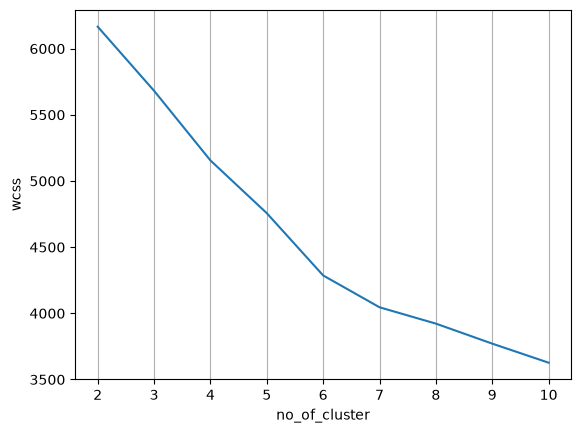

In [354]:
plt.plot([i for i in range(2,11)], wcss)
plt.xlabel("no_of_cluster")
plt.xticks([i for i in range(2,11)])
plt.ylabel("wcss")
plt.grid(axis="x")
plt.show()

In [355]:
km = KMeans(n_clusters=4, random_state=42, init="k-means++")
x_scaled["predict"] = km.fit_predict(x_scaled)

Task	Suggested final model	Why
Predict price	Linear regression (or Ridge) in a scaler pipeline	About 63–65% CV R², simple, and no overfitting. Random Forest (about 62%) is a fine alternative.
Predict price category	Logistic regression or SVM pipeline	About 59% CV accuracy, the best of your classifiers.
House segment K-means (k=4) with its scaler	Shows which of the four groups the house belongs to.

In [356]:
import joblib, pandas as pd
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("Housing.csv")
for c in ["mainroad","guestroom","basement","hotwaterheating","airconditioning","prefarea"]:
    df[c] = df[c].map({"yes": 1, "no": 0})
df = pd.get_dummies(df, columns=["furnishingstatus"], drop_first=True, dtype=int)

df["price_category"] = pd.qcut(df["price"], q=4, labels=["Low","Medium","High","Very High"])
X = df.drop(columns=["price","price_category"])
features = X.columns.tolist()

reg = make_pipeline(StandardScaler(), LinearRegression()).fit(X, df["price"])
clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X, df["price_category"])
seg = make_pipeline(StandardScaler(), KMeans(n_clusters=4, random_state=42, n_init=10)).fit(X)

# name clusters by average price (cheapest -> most expensive), so names never depend on cluster ids
order = df.groupby(seg.predict(X))["price"].mean().sort_values().index.tolist()
names = ["Basic budget homes", "Mid-range semi-furnished homes", "Large homes with basement and guestroom", "Premium multi-storey homes"]
segment_names = {int(c): n for c, n in zip(order, names)}

joblib.dump({"reg": reg, "clf": clf, "seg": seg, "features": features,
             "segment_names": segment_names,
             "area_range": (int(df.area.min()), int(df.area.max()))}, "house_models.joblib")
print("saved", features, segment_names)

saved ['area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus_semi-furnished', 'furnishingstatus_unfurnished'] {1: 'Basic budget homes', 2: 'Mid-range semi-furnished homes', 3: 'Large homes with basement and guestroom', 0: 'Premium multi-storey homes'}
